# Семинар 4. BERT: классификация тональности и извлечение сущностей

**Практикум для Google Colab · самостоятельная работа в парах**

Решения заданий заполнены. Выполняйте ячейки последовательно в Google Colab с GPU. Для тональности используются 4000 сообщений, для NER — полный WikiANN; CSV скачиваются автоматически. Метрики и прогнозы появятся после запуска обучения.

Мы применим предобученный Encoder к двум разным задачам:

- **Классификация текста:** один прогноз на всё сообщение (положительный / отрицательный).
- **NER:** отдельная метка для каждого токена (PER / ORG / LOC / O).

**Среда:** Colab → *Среда выполнения → Сменить среду выполнения → GPU* (если доступен).

## 1. BERT: что именно мы дообучаем?

**BERT** (*Bidirectional Encoder Representations from Transformers*) — модель на основе **Transformer Encoder**. При обработке входа каждый токен может учитывать информацию слева и справа благодаря двунаправленному Self-Attention.

### Как BERT получил языковые знания

На стадии **pretraining** оригинальный BERT обучался на больших текстовых корпусах, без разметки тональности:

- **MLM (Masked Language Modeling):** выбираем часть позиций токенов и учим модель предсказывать исходный токен по окружению. В оригинальном BERT выбирали 15% позиций; среди них 80% заменяли на `[MASK]`, 10% — на случайный токен, 10% — оставляли без замены.
- **NSP (Next Sentence Prediction):** модель различала пары, где второй фрагмент действительно следует за первым в корпусе, и пары со случайным вторым фрагментом. В последующих BERT-подобных моделях NSP используется не всегда.

**Fine-tuning** — это следующий этап: мы берём предобученные веса Encoder и учим модель решать конкретную задачу по размеченным примерам, обновляя веса модели и выходной головы.

Например, вместо восстановления `[MASK]` теперь нужно предсказать `positive` или `negative`.

**Материалы:** [BERT — оригинальная статья](https://arxiv.org/abs/1810.04805) · [The Illustrated BERT](https://jalammar.github.io/illustrated-bert/) · [Hugging Face: классификация текста](https://huggingface.co/docs/transformers/tasks/sequence_classification).

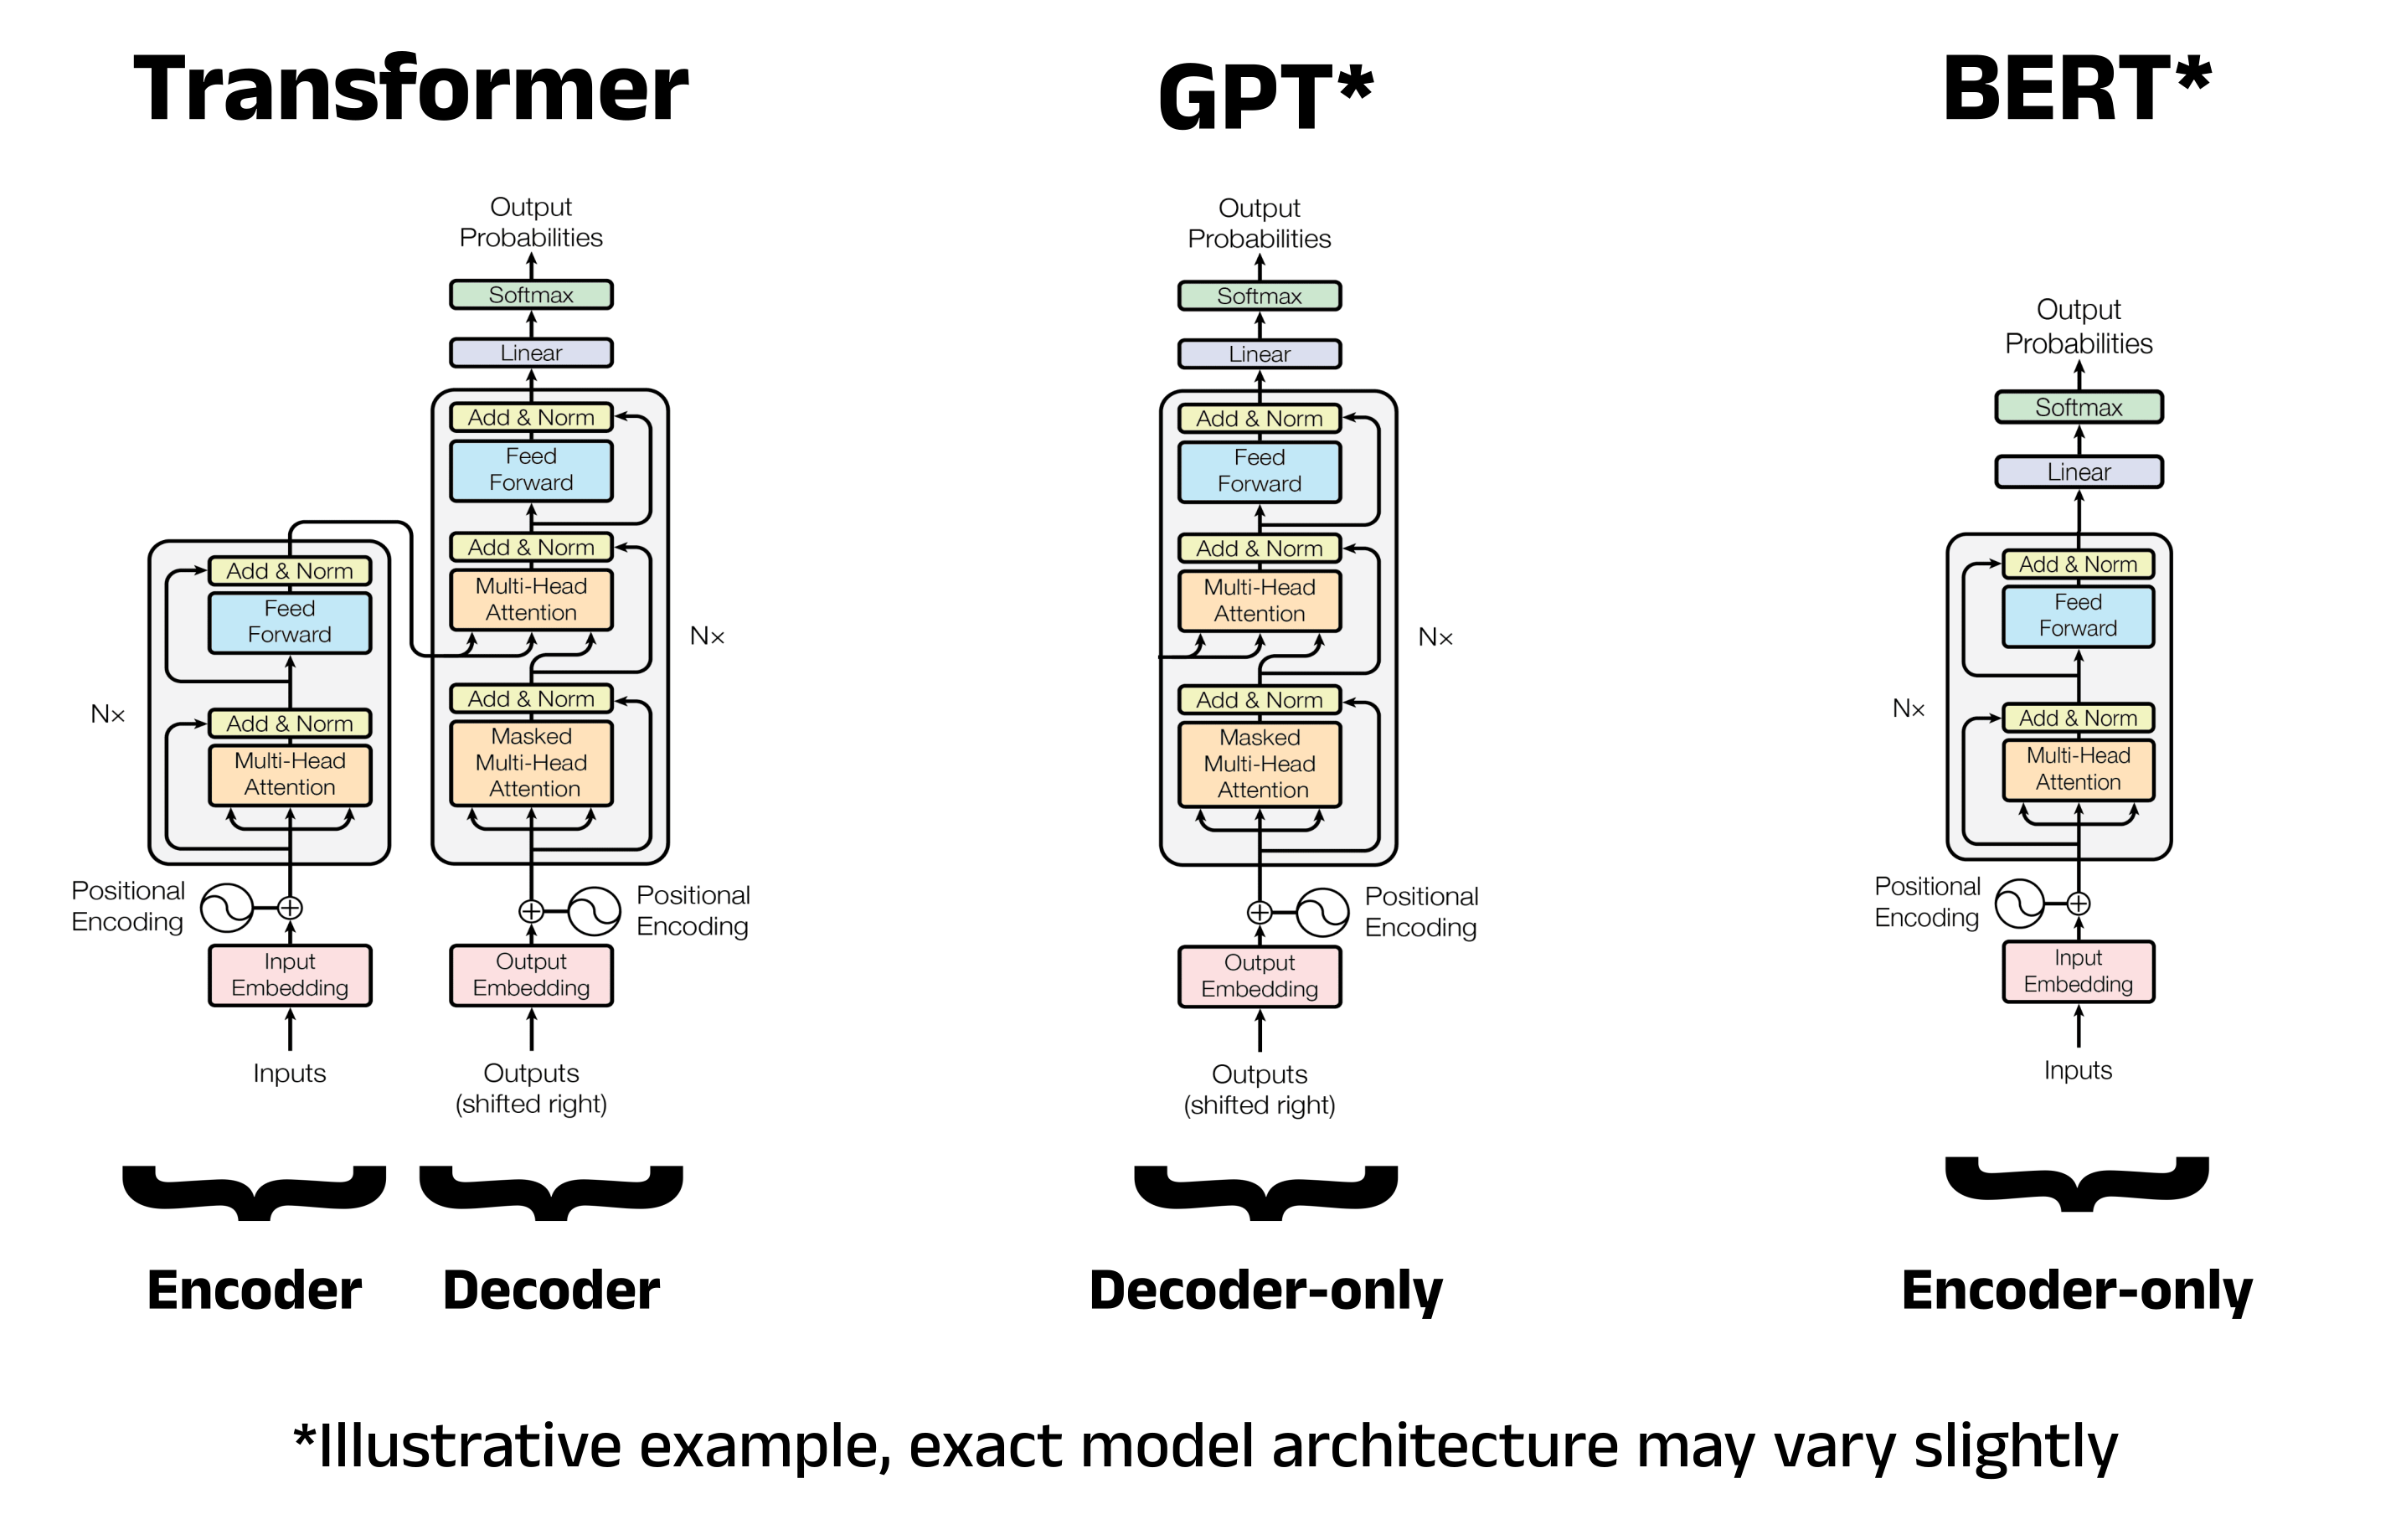

### Одна архитектура — две разные задачи

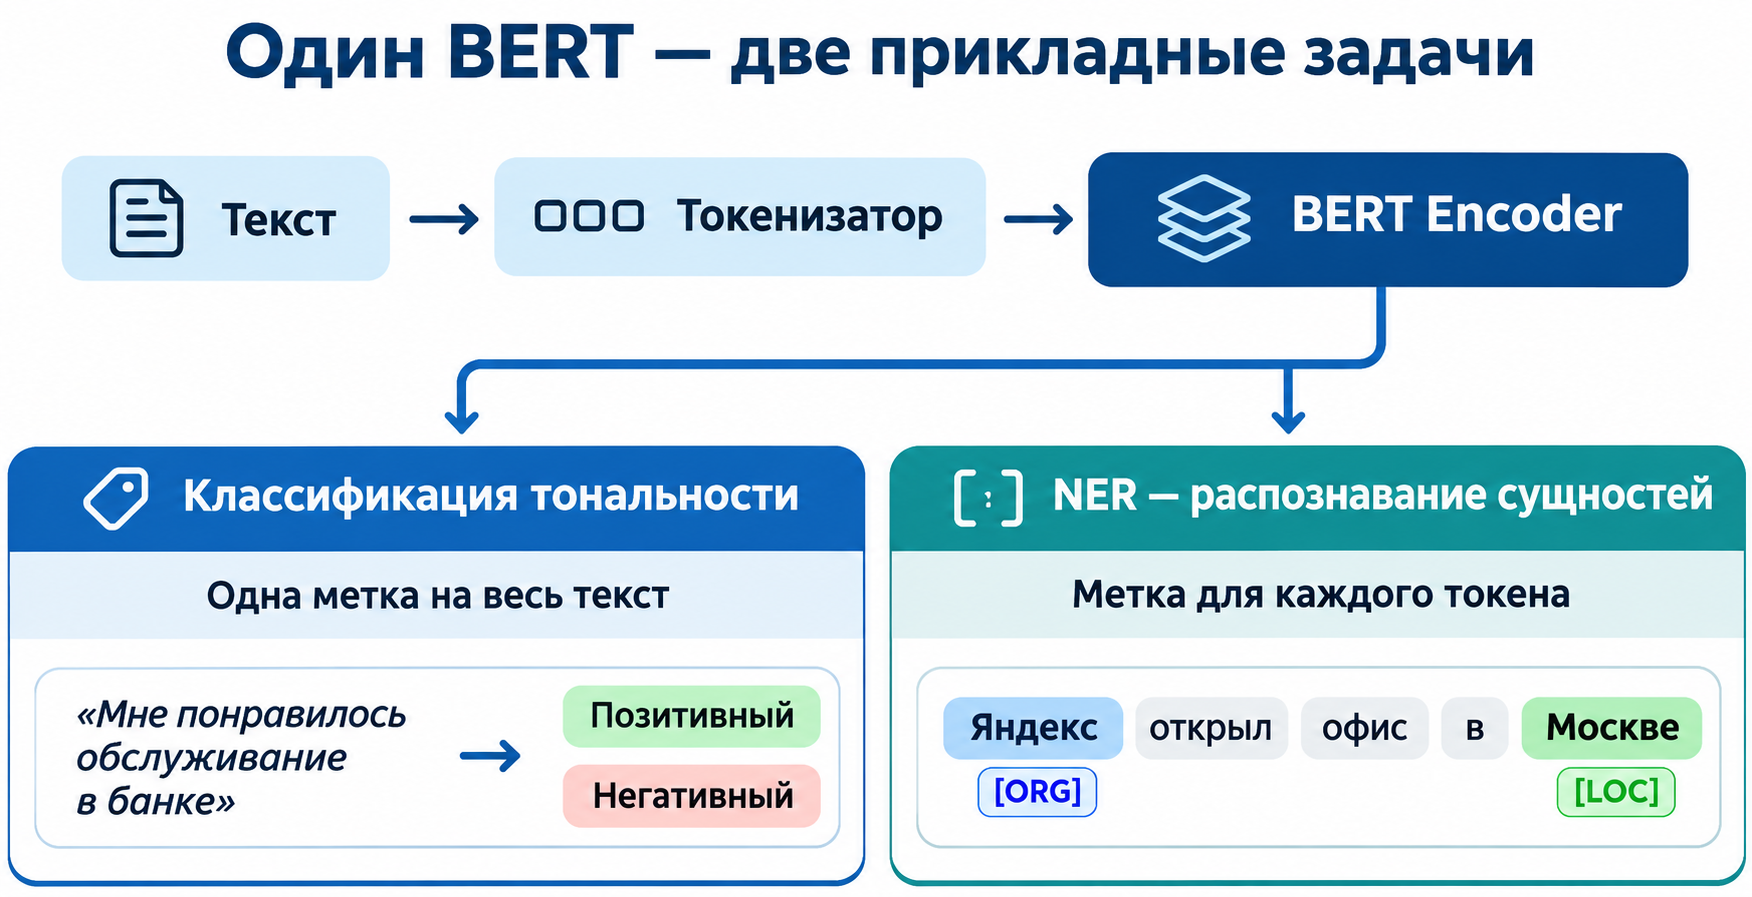

*Схема концептуальная: в каждой задаче к BERT добавляют свою выходную голову; в NER предсказания для подтокенов затем объединяют в сущности.*

### Почему нужны разные выходные головы?

В **Sequence Classification** один текст получает одну метку: из представления последовательности модель вычисляет два `logits`. В **Token Classification** метка предсказывается для каждого токена. **Encoder похожий, цель обучения разная.**

Сначала попробуем классификацию тональности, затем усложним задачу и перейдём к NER.

## 2. Настройка окружения

В Colab библиотеки могут меняться от запуска к запуску. Для стабильности используем совместимое семейство Transformers 4.x; при необходимости после установки перезапустите среду выполнения. В двух следующих ячейках дан стартовый код — его можно выполнить без изменений.

In [ ]:
%pip -q install "transformers>=4.46,<5" "datasets>=3,<5" "accelerate>=0.26" "evaluate" "seqeval" "scikit-learn" "pandas" "matplotlib"

In [ ]:
from urllib.request import urlretrieve
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import Dataset, DatasetDict, load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForTokenClassification,
    DataCollatorWithPadding,
    DataCollatorForTokenClassification,
    TrainingArguments,
    Trainer,
    pipeline,
    set_seed,
)
import evaluate

SEED = 42
set_seed(SEED)
MODEL_ID = "cointegrated/rubert-tiny2"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

---
# Практика 1. Классификация тональности сообщений

**Прикладная задача:** по тексту русскоязычного сообщения определить положительную (`1`) или отрицательную (`0`) тональность. Обучаем **только BERT** — без TF-IDF и сравнительных моделей.

### Данные — RuTweetCorp

- [positive.csv](https://github.com/kategimranova/tonal_russian_texts/blob/master/dataset/positive.csv)
- [negative.csv](https://github.com/kategimranova/tonal_russian_texts/blob/master/dataset/negative.csv)
- [Оба файла в репозитории](https://github.com/kategimranova/tonal_russian_texts/tree/master/dataset)
- [RuTweetCorp — Kaggle](https://www.kaggle.com/datasets/maximsuvorov/rutweetcorp)

Следующая ячейка скачивает оба CSV напрямую из репозитория. Файлы **без заголовка**, с разделителем `;`, а текст в столбце с индексом **3**. Первые строки выводятся для проверки. Метки получены автоматически и могут быть шумными.

**Ожидаемый результат:** таблица `df` с двумя столбцами: `text` и `label`.

### Шаг 1. Загружаем данные и проверяем формат

**Зачем:** если ошибиться с разделителем или индексом текстового столбца, модель будет учиться на неправильных данных.

**Допишите:** чтение второго файла, выбор текстового столбца, присвоение классов и объединение. После этого посмотрите первые строки.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/kategimranova/tonal_russian_texts/master/dataset"
for filename in ("positive.csv", "negative.csv"):
    urlretrieve(f"{DATA_URL}/{filename}", filename)

positive = pd.read_csv("positive.csv", sep=";", header=None)
negative = pd.read_csv("negative.csv", sep=";", header=None)

print("Форма positive:", positive.shape)
print(positive.iloc[:2, :5])

pos_df = pd.DataFrame({"text": positive[3], "label": 1})
neg_df = pd.DataFrame({"text": negative[3], "label": 0})

df = pd.concat([pos_df, neg_df], ignore_index=True)
display(df.head())

### Шаг 2. Исследуем распределение классов

**Теория:** модель должна получить тексты и целевые метки; важно проверить пропуски, дубликаты и баланс классов. При сильном дисбалансе одной Accuracy недостаточно.

**Допишите:** очистку пустых текстов и подсчёт числа объектов каждого класса. Старайтесь не удалять эмодзи и пунктуацию без причины: для тональности они могут быть важны.

In [ ]:
df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].str.strip()
df = df[df["text"].ne("")]
# Удаляем все экземпляры текстов с противоречивыми метками.
label_counts = df.groupby("text")["label"].transform("nunique")
df = df[label_counts.eq(1)].drop_duplicates("text").reset_index(drop=True)

print("Размер корпуса:", len(df))
print("Количество пропусков:")
print(df.isna().sum())
print("Распределение меток:")
display(df["label"].value_counts().sort_index().rename_axis("label").to_frame("count"))

display(df.groupby("label").sample(3, random_state=SEED))

### Шаг 3. Разделяем данные без утечки

**Теория:** train используется для изменения весов, validation — для настройки обучения, test — **один раз** для финальной оценки. Если один и тот же текст попал в train и test, оценка будет слишком оптимистичной.

Берём **4000 сообщений** из очищенного корпуса со стратификацией по меткам. Делим их на 3200/400/400 для train/validation/test, сохраняя баланс классов. Разбиение делаем **до токенизации**.

**Допишите:** `train_test_split(..., stratify=...)`, фиксируйте `random_state=SEED`.

In [ ]:
work_df, _ = train_test_split(
    df, train_size=4000, random_state=SEED, stratify=df["label"]
)

# train = 80%, а оставшиеся 20% делим пополам на val и test
train_df, temp_df = train_test_split(
    work_df,
    test_size=0.2,
    random_state=SEED,
    stratify=work_df["label"],
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=SEED, stratify=temp_df["label"]
)
assert set(train_df.text).isdisjoint(val_df.text)
assert set(train_df.text).isdisjoint(test_df.text)
assert set(val_df.text).isdisjoint(test_df.text)

print("train / val / test:", len(train_df), len(val_df), len(test_df))

### Шаг 4. Что делает токенизатор BERT?

Токенизатор превращает строки в `input_ids` и `attention_mask`. **`input_ids`** — номера токенов в словаре модели, **`attention_mask`** отличает содержательные позиции от добавленного padding. **`truncation`** ограничивает длину, иначе длинные тексты не поместятся в выбранное окно.

**Перед запуском:** предположите, всегда ли одно слово превращается в один токен. Проверьте на своём примере.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
example = "Мне очень понравилось обслуживание, спасибо!"

encoded = tokenizer(example, truncation=True, max_length=128)

print("Подтокены:", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print("input_ids:", encoded["input_ids"])
print("attention_mask:", encoded["attention_mask"])

### Шаг 5. Готовим датасет для `Trainer`

`Trainer` работает с наборами, содержащими признаки (`input_ids`, `attention_mask`) и целевые метки (`label`/`labels`). Удобно перейти от Pandas к `datasets.Dataset` и применить токенизацию ко всему набору через `.map()`.

**Допишите:** три датасета и функцию токенизации. *Padding* можно делать динамически с помощью `DataCollatorWithPadding`, чтобы не заполнять все строки до максимальной длины заранее.

In [ ]:
def tokenize_sentiment(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

sentiment_ds = DatasetDict({
    "train": Dataset.from_pandas(train_df, preserve_index=False),
    "validation": Dataset.from_pandas(val_df, preserve_index=False),
    "test": Dataset.from_pandas(test_df, preserve_index=False),
})

sentiment_tok = sentiment_ds.map(tokenize_sentiment, batched=True, remove_columns=["text"])

sentiment_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(sentiment_tok["train"][0].keys())

### Шаг 6. Подключаем классификационную голову

**Почему не `AutoModel`?** Для готовой задачи классификации нужен `AutoModelForSequenceClassification`: модель добавляет обучаемый слой, который возвращает **два logits**. По ним можно получить предсказанный класс.

На этом этапе часть новых весов инициализируется случайно — это нормально: в ходе fine-tuning они научатся различать классы.

**Допишите:** загрузку модели и один пробный прямой проход (`forward`) с `torch.no_grad()` до обучения.

In [ ]:
model_sent = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=2,
    id2label={0: "negative", 1: "positive"},
    label2id={"negative": 0, "positive": 1},
)

inputs = {key: torch.tensor([value]) for key, value in encoded.items()}
model_sent.eval()
with torch.no_grad():
    logits = model_sent(**inputs).logits
print("Logits:", logits, "Форма:", logits.shape)
assert logits.shape == (1, 2)

### Шаг 7. Fine-tuning через `Trainer`

**Теория:** в каждой эпохе модель получает batch, вычисляет loss, градиенты обновляют параметры. Мы измеряем качество на validation, а test пока не используем.

**Параметры для первого запуска:** `learning_rate=2e-5`, `num_train_epochs=2`, `per_device_train_batch_size=8`, `eval_strategy="epoch"`, `save_strategy="no"`, `report_to="none"`.

**Допишите:** метрики Accuracy и Macro-F1, недостающие аргументы Trainer и запуск `.train()`. Если Colab работает на CPU, сократите выборку. Обратите внимание: в актуальном API используется `eval_strategy`, а токенизатор передают через `processing_class`.

In [ ]:
def compute_sentiment_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    f1 = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)[2]
    return {"accuracy": accuracy_score(labels, preds), "macro_f1": f1}

args_sent = TrainingArguments(
    output_dir="./bert-sentiment",
    seed=SEED,
    learning_rate=2e-5,
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
)

trainer_sent = Trainer(
    model=model_sent,
    args=args_sent,
    train_dataset=sentiment_tok["train"],
    eval_dataset=sentiment_tok["validation"],
    processing_class=tokenizer,
    data_collator=sentiment_collator,
    compute_metrics=compute_sentiment_metrics,
)

trainer_sent.train()
display(pd.DataFrame(trainer_sent.state.log_history))

### Шаг 8. Проверяем модель на тестовой выборке

**Теория:** финальная оценка на тесте нужна после выбора модели и гиперпараметров. Помимо Accuracy рассчитайте Precision, Recall и F1. Для двух классов Macro-F1 усредняет F1 по классам с равными весами.

**Допишите:** получение `logits`, преобразование в метки через `argmax`, таблицу метрик и матрицу ошибок.

In [ ]:
pred_output = trainer_sent.predict(sentiment_tok["test"])
y_pred = np.argmax(pred_output.predictions, axis=-1)
y_true = pred_output.label_ids

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
display(pd.DataFrame([{
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision, "Macro Recall": recall, "Macro F1": f1,
}]))

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["negative", "positive"])
plt.show()
errors = test_df.assign(predicted=y_pred)
display(errors[errors.label.ne(errors.predicted)].head(3))

### Шаг 9. Пробуем на собственных сообщениях

Для демонстрации бизнес-задачи предскажите тональность нескольких новых фраз. **Не включайте их в train/test**. Обязательно проверьте сообщения с отрицанием, иронией и неоднозначным настроением.

**В паре:** выберите минимум три ошибочных или спорных прогноза и объясните, почему BERT мог ошибиться.

In [ ]:
new_texts = [
    "Приложение работает отлично, всё понравилось!",
    "Не могу войти уже третий день, ужасный сервис.",
    "Ну спасибо, опять всё сломалось.",
    "Не скажу, что мне понравилось.",
    "Доставка быстрая, но товар сломан.",
]

inputs = tokenizer(new_texts, padding=True, truncation=True, max_length=128, return_tensors="pt")
inputs = inputs.to(model_sent.device)
model_sent.eval()
with torch.no_grad():
    probabilities = model_sent(**inputs).logits.softmax(dim=-1)
confidence, predictions = probabilities.max(dim=-1)
display(pd.DataFrame({
    "text": new_texts,
    "label": [model_sent.config.id2label[i] for i in predictions.tolist()],
    "confidence": confidence.cpu().tolist(),
}))

# Три спорных случая: причины возможных ошибок, а не утверждение об их наличии.
display(pd.DataFrame({
    "text": new_texts[2:],
    "риск ошибки": [
        "Ирония: положительное «спасибо» противоречит жалобе на поломку.",
        "Косвенное отрицание: «не скажу» меняет смысл слова «понравилось».",
        "Смешанная оценка: положительная доставка, но отрицательная оценка товара.",
    ],
}))

---
# Практика 2. NER: распознаём людей, организации и места

**Прикладная задача:** система мониторинга новостей получает текст и должна извлечь сущности **PER** (люди), **ORG** (организации), **LOC** (география).

Мы используем тот же тип Encoder, но другую голову: `AutoModelForTokenClassification`, которая выдаёт прогноз для **каждого токена**.

### Датасет WikiANN — русский язык

- [Карточка WikiANN](https://huggingface.co/datasets/unimelb-nlp/wikiann)
- [Русская часть WikiANN](https://huggingface.co/datasets/unimelb-nlp/wikiann/tree/main/ru)
- [Hugging Face — Token Classification](https://huggingface.co/docs/transformers/tasks/token_classification)

WikiANN содержит слова (`tokens`) и их метки (`ner_tags`). Мы используем конфигурацию `ru` и сохраняем независимость train/validation/test.

**Пример:** «Александр Иванов работает в Яндексе» → `B-PER`, `I-PER`, `O`, `O`, `B-ORG`.

### Шаг 10. BIO-разметка

В NER надо определить не просто тип слова, а **границы сущности**:

| Метка | Значение |
|---|---|
| `O` | вне сущности |
| `B-PER` / `I-PER` | начало / продолжение имени |
| `B-ORG` / `I-ORG` | начало / продолжение организации |
| `B-LOC` / `I-LOC` | начало / продолжение географического названия |

**Обсудите:** почему «Александр Иванов» — одна сущность, хотя состоит из двух слов?

**Допишите:** загрузку русской конфигурации и просмотр одной записи с расшифровкой меток.

In [ ]:
wiki = load_dataset("unimelb-nlp/wikiann", "ru")
print(wiki)

label_names = wiki["train"].features["ner_tags"].feature.names
print(label_names)

sample = wiki["train"][0]
for word, tag_id in zip(sample["tokens"], sample["ner_tags"]):
    print(word, label_names[tag_id])

### Шаг 11. Используем полный WikiANN

Используем все записи русской конфигурации со штатными train/validation/test. **Не смешиваем разделения** и не подбираем гиперпараметры по test.

`ner_ds` содержит полные разделения без сокращения.

In [ ]:
ner_ds = wiki

print(ner_ds)

### Шаг 12. Почему возникает проблема с подтокенами?

Разметка WikiANN находится **на уровне слов**, а токенизатор может разбить одно слово на несколько subtokens. Поэтому список `ner_tags` не всегда совпадает по длине с `input_ids`.

Нужно сопоставить каждому подтокену исходное слово через `word_ids()`. Для `[CLS]`, `[SEP]` и других специальных токенов метку задают `-100`: такую позицию PyTorch игнорирует в функции потерь.

**Упрощённое учебное правило:** метку слова ставим только **первому** подтокену; остальные части того же слова помечаем `-100`. Это правило можно заменить другой политикой, но её нужно применять последовательно.

**Допишите:** выведите `word_ids()` и сравните длины.

In [ ]:
example_words = ["Александр", "Иванов", "встретился", "с", "руководителем", "Яндекса"]
example_enc = tokenizer(example_words, is_split_into_words=True, truncation=True)

print(tokenizer.convert_ids_to_tokens(example_enc["input_ids"]))
print("word_ids:", example_enc.word_ids())
print("Слов / подтокенов:", len(example_words), len(example_enc["input_ids"]))

# None соответствует специальным токенам, не связанным с исходными словами.
print("Специальные позиции:", [i for i, word_id in enumerate(example_enc.word_ids()) if word_id is None])

### Шаг 13. Выравниваем метки с токенами

Это ключевое упражнение второй практики. Функция получает batch из `tokens` и `ner_tags`, затем токенизирует каждую последовательность. Для каждой позиции определяет, является ли она первым подтокеном исходного слова.

**Допишите только внутреннюю логику** цикла и присвоение `labels`. Проверьте, что длины `input_ids` и `labels` всегда совпадают.

In [ ]:
def tokenize_and_align_labels(examples):
    tokenized = tokenizer(
        examples["tokens"],
        is_split_into_words=True,
        truncation=True,
        max_length=128,
    )
    aligned_labels = []

    for batch_index, word_labels in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index=batch_index)
        previous_word_id = None
        current_labels = []

        for word_id in word_ids:
            if word_id is None or word_id == previous_word_id:
                current_labels.append(-100)
            else:
                current_labels.append(word_labels[word_id])
            previous_word_id = word_id

        aligned_labels.append(current_labels)

    tokenized["labels"] = aligned_labels
    return tokenized

ner_tok = ner_ds.map(
    tokenize_and_align_labels, batched=True, remove_columns=ner_ds["train"].column_names
)

for split in ner_tok.values():
    assert all(len(ids) == len(labels) for ids, labels in zip(split["input_ids"], split["labels"]))
print("input_ids / labels:", len(ner_tok["train"][0]["input_ids"]), len(ner_tok["train"][0]["labels"]))

### Шаг 14. Дообучаем BERT для NER

**В чём отличие от первой практики?** Классификационная голова теперь выдаёт логиты размера `(batch, seq_len, num_labels)`. `DataCollatorForTokenClassification` выравнивает длины входов и `labels` внутри batch.

**Качество:** для NER используем `seqeval` и **entity-level F1** — оценка учитывает тип и границы распознанной сущности, а не только долю правильно размеченных токенов.

**Допишите:** загрузку модели, функцию метрик и обучение. В `compute_metrics` не включайте позиции с правильной меткой `-100`.

In [ ]:
id2label = {i: name for i, name in enumerate(label_names)}
label2id = {name: i for i, name in enumerate(label_names)}

model_ner = AutoModelForTokenClassification.from_pretrained(
    MODEL_ID,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id,
)
ner_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)
seqeval = evaluate.load("seqeval")

def compute_ner_metrics(eval_pred):
    logits, labels = eval_pred
    pred_ids = np.argmax(logits, axis=-1)
    true_predictions = [
        [label_names[p] for p, tag in zip(pred, target) if tag != -100]
        for pred, target in zip(pred_ids, labels)
    ]
    true_labels = [
        [label_names[tag] for tag in target if tag != -100] for target in labels
    ]
    scores = seqeval.compute(predictions=true_predictions, references=true_labels)
    return {name: scores[f"overall_{name}"] for name in ("precision", "recall", "f1")}

args_ner = TrainingArguments(
    output_dir="./bert-ner",
    seed=SEED,
    learning_rate=3e-5,
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
)
trainer_ner = Trainer(
    model=model_ner,
    args=args_ner,
    train_dataset=ner_tok["train"],
    eval_dataset=ner_tok["validation"],
    data_collator=ner_collator,
    processing_class=tokenizer,
    compute_metrics=compute_ner_metrics,
)

trainer_ner.train()
display(pd.DataFrame(trainer_ner.state.log_history))

### Шаг 15. Проверяем NER и создаём мини-сервис «Новостной аналитик»

Финальный этап — получить **список сущностей**, а не только метрики. Используем `pipeline(task="token-classification", aggregation_strategy="first")`: метка первого подтокена распространяется на слово, затем BIO-метки объединяются в сущности. Это согласуется с правилом обучения, где остальные подтокены игнорируются.

**Допишите:** оценку на test, запуск на собственных новостях и функцию `extract_entities(text)` с результатом вида `{"PER": [...], "ORG": [...], "LOC": [...]}`.

Проверьте минимум три предложения, в том числе одно с несколькими словами в названии организации или места.

In [ ]:
ner_test_metrics = trainer_ner.evaluate(ner_tok["test"], metric_key_prefix="test")
print(ner_test_metrics)

ner_pipe = pipeline(
    "token-classification",
    model=model_ner,
    tokenizer=tokenizer,
    aggregation_strategy="first",
    device=0 if torch.cuda.is_available() else -1,
)

text_example = "Яндекс открыл новый офис в Москве."
print(ner_pipe(text_example))

def extract_entities(text):
    """Извлекает людей, организации и места с сохранением исходного написания."""
    result = {"PER": [], "ORG": [], "LOC": []}
    for entity in ner_pipe(text):
        result[entity["entity_group"]].append(text[entity["start"]:entity["end"]])
    return result

news = [
    "Сергей Иванов встретился с представителями Яндекса в Москве.",
    "Анна Смирнова выступила в Национальном исследовательском университете «Высшая школа экономики».",
    "Михаил Петров посетил Нижний Новгород и обсудил проект со Сбербанком.",
]
for text in news:
    print(text)
    print(extract_entities(text))

---
## Итог: что необходимо сдать

**Практика 1 (тональность):** таблица классов; корректное разделение train/validation/test; обученная BERT-модель; Accuracy, Precision, Recall и Macro-F1 на test; матрица ошибок и разбор минимум трёх сообщений.

**Практика 2 (NER):** пример BIO-разметки, демонстрация `word_ids()`, выравнивание меток, дообученная модель, entity-level Precision/Recall/F1 и работающая `extract_entities(text)` на трёх собственных новостях.

### Самопроверка

- Почему при переходе от sentiment к NER меняется класс выходной головы?
- Для чего NER использует `-100` в метках?
- Почему F1 по сущностям строже обычной доли верных токенов?
- Какие ошибки обнаружились в коротких сообщениях и новостях?

**Дополнительно:** попробуйте изменить **один** гиперпараметр (`max_length`, learning rate или число эпох), не используя test при подборе, и объяснить изменение результата.

**Справочные материалы:** [BERT Illustrated](https://jalammar.github.io/illustrated-bert/) · [Sequence Classification](https://huggingface.co/docs/transformers/tasks/sequence_classification) · [Token Classification](https://huggingface.co/docs/transformers/tasks/token_classification).